# RAGF-BERT v5 - one model, layer-level techniques (no ensemble)

**Colab:** `Runtime -> Change runtime type -> T4 GPU`, `Run all`, upload `sarcasm_balanced_9600_full.csv` when asked.

**Single `bert-base-uncased` model.** No ensemble. The notebook trains the *same* model with different **layer-level treatments** and compares them on the same split, over several seeds:

| Variant | What it does to the BERT layers |
|---|---|
| Full fine-tuning | plain baseline, no rationale loss |
| Attention supervision | paper-style: last-layer [CLS] attention is trained toward the human rationale (lambda = 1.0) |
| + LLRD | layer-wise learning-rate decay: lower layers move less than upper layers |
| + re-init top 2 | re-initialise the top 2 encoder layers (they are the most task-specific) |
| + weighted layer pooling | classify from a learned mix of the [CLS] vectors of the last 4 layers |
| + multi-sample dropout | 5 dropout masks on the classifier head, averaged |
| + gradual unfreezing | train top 4 layers first, then 8, then all |
| + static freeze 3 | bottom 3 layers frozen for the whole run |
| RAGF-BERT | attention supervision + dynamic gradient-guided layer freezing |
| COMBO | LLRD + re-init + weighted pooling + multi-sample dropout |

**Selection rule:** the best variant is chosen by mean **validation** macro-F1 only; the test set is read once for reporting. A paired t-test over seeds shows whether a variant really beats the attention-supervision baseline. Fixes from v4 are kept (rationale loaded from `hate_rationale_weights`, `paper_split`, clean 3/3 extra posts, span IOU-F1).

**Be aware:** none of these techniques is guaranteed to help. The notebook reports the result either way.


## 0. Experimental protocol

The notebook first checks whether valid human token-level rationales are available.

- With gold rationales: run full fine-tuning, static freezing, adaptive classification, adaptive rationale, and dual-objective RAGF-BERT.
- Without gold rationales: run full fine-tuning, static freezing, and adaptive classification; skip rationale-supervised runs without crashing. Generate illustrative model-based token explanations, but do not claim rationale plausibility improvements.

All methods use the same train/validation/test split. Results are measured on the held-out test set. Published paper scores are shown separately as contextual references, not as a matched baseline.


In [1]:
# Google Colab dependency setup — compatible with the current Colab Hugging Face stack.
# IMPORTANT:
# - Do not upgrade pip/setuptools blindly.
# - Do not install the old datasets/accelerate pins; this notebook does not use them.
# - Keep Colab's preinstalled PyTorch/CUDA untouched.
#
# Colab's current Transformers 5.x stack requires:
#   huggingface-hub >=1.31,<3
#   tokenizers >=0.23.1,<0.24
# We pin a mutually compatible set and request wheels only (no Rust compilation).

!python -m pip install -q --only-binary=:all: \
    "setuptools<82" "jedi>=0.16" \
    "huggingface-hub>=1.31,<3" \
    "tokenizers>=0.23.1,<0.24" \
    "transformers==5.21.0" \
    scikit-learn pandas numpy matplotlib seaborn

# Verify versions and imports. Restart runtime if Colab asks you to.
import sys, torch, transformers, tokenizers, huggingface_hub
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("CUDA available:", torch.cuda.is_available())


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
Transformers: 5.21.0
Tokenizers: 0.23.3
Hugging Face Hub: 1.33.0
CUDA available: True


In [2]:
import os, re, gc, json, math, random, glob, copy, warnings, hashlib, time
from dataclasses import dataclass
from typing import List, Dict, Optional, Tuple
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             auc)
import matplotlib.pyplot as plt
import seaborn as sns

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0), torch.cuda.get_device_properties(0).total_memory/1024**3, "GB")

Device: cuda
Tesla T4 14.56317138671875 GB


## 1. Configuration and Colab paths

The next cells look in `/content` and Google Drive. You can upload files when prompted, or mount Drive and set the paths below. The notebook accepts your sarcasm CSV without requiring HateXplain to be present.


In [3]:
# ---- Google Colab configuration ----
import os, glob

# Optional: mount Google Drive if your datasets are stored there.
USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

# If your files are in Drive, put their exact paths here.
USER_CSV_PATH = ""       # e.g. "/content/drive/MyDrive/data/sarcasm_balanced_9600.csv"
HATEXPLAIN_PATHS = []    # e.g. ["/content/drive/MyDrive/HateXplain/train.json", ...]

# Model/training configuration
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 4
WARMUP_FRACTION = 0.10
LR = 3e-5
WEIGHT_DECAY = 0.01
DROPOUT = 0.1
SEED = 42
NUM_WORKERS = 2
GRAD_ACCUM_STEPS = 1
MAX_GRAD_NORM = 1.0

# Dynamic policy settings (tune only on validation, never test)
MONITOR_EVERY_STEPS = 100
MIN_WARMUP_STEPS = 100
EMA_BETA = 0.8
FREEZE_PATIENCE = 3
UNFREEZE_PATIENCE = 2
FREEZE_QUANTILE = 0.20
UNFREEZE_IMPORTANCE_MULTIPLIER = 1.5
MIN_TRAINABLE_ENCODER_LAYERS = 4
MAX_FROZEN_ENCODER_LAYERS = 8
RAGF_MODE = "both"   # "both", "classification", "rationale", "none"
STATIC_FREEZE_BOTTOM = 0  # 0, 3, or 6 for static baselines

LAMBDA_RATIONALE = 1.0      # v4: was 0.001 (too small to have any effect)
LABEL_SMOOTHING = 0.0
RATIONALE_COLUMNS_CANDIDATES = [
    "rationale", "rationales", "sarcasm_rationale",
    "hate_rationale", "explanation"
]
# ---- v4 additions ----
SARCASM_RATIONALE_WEIGHT = 0.5   # rationale target = hate weight + 0.5 x sarcasm mask (as in the paper's combined rationale)
USE_PAPER_SPLIT = True           # use the CSV's paper_split (train / validation / test)
EXTRA_AGREE = "3/3"              # keep only extra HateXplain posts with 3/3 annotator agreement (None = all)
EXTRA_PLATFORM = None            # "gab" = drop extra Twitter posts
GOLD_THR = 0.5                   # human rationale word = hate weight >= 0.5
TEXT_COL = "text"
LABEL_COL = "label"

OUTPUT_DIR = "/content/ragf_bert"
os.makedirs(OUTPUT_DIR, exist_ok=True)


In [4]:
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

## 2. Load and inspect datasets

You need at least one compatible dataset. The user's CSV is sufficient to run the classification experiments. HateXplain is optional but recommended for human-rationale supervision.

The canonical target classes are `hate`, `offensive`, and `normal`. Label mapping must be reviewed. We do not infer a distinction that the source labels do not provide.


In [5]:
# Find or upload the user's CSV and optional HateXplain files.
from pathlib import Path

def find_named_file(name, roots=("/content", "/content/drive/MyDrive")):
    for root in roots:
        if os.path.isdir(root):
            hits = glob.glob(os.path.join(root, "**", name), recursive=True)
            if hits:
                return hits[0]
    return None

if not USER_CSV_PATH or not os.path.isfile(USER_CSV_PATH):
    USER_CSV_PATH = find_named_file("*sarcasm_balanced_9600*.csv")

if USER_CSV_PATH is None:
    print("Upload your sarcasm_balanced_9600.csv now. You may also select HateXplain JSON files in the same upload dialog.")
    from google.colab import files
    uploaded = files.upload()
    uploaded_paths = [os.path.join("/content", name) for name in uploaded.keys()]
    csv_hits = [p for p in uploaded_paths if p.lower().endswith(".csv") and "sarcasm" in os.path.basename(p).lower()]
    if not csv_hits:
        csv_hits = [p for p in uploaded_paths if p.lower().endswith(".csv")]
    if csv_hits:
        USER_CSV_PATH = csv_hits[0]
    HATEXPLAIN_PATHS = HATEXPLAIN_PATHS + [
        p for p in uploaded_paths if p.lower().endswith((".json", ".jsonl"))
    ]

print("User CSV path:", USER_CSV_PATH)
if USER_CSV_PATH and os.path.isfile(USER_CSV_PATH):
    user_raw = pd.read_csv(USER_CSV_PATH)
    print("User CSV shape:", user_raw.shape)
    print("Columns:", list(user_raw.columns))
    display(user_raw.head())
    for c in user_raw.columns:
        if user_raw[c].nunique(dropna=True) < 30:
            print(c, user_raw[c].value_counts(dropna=False).head(20).to_dict())
else:
    user_raw = None
    print("No user CSV found. Upload it or set USER_CSV_PATH in the configuration cell.")


Upload your sarcasm_balanced_9600.csv now. You may also select HateXplain JSON files in the same upload dialog.


Saving sarcasm_balanced_9600_full.csv to sarcasm_balanced_9600_full.csv
User CSV path: /content/sarcasm_balanced_9600_full.csv
User CSV shape: (9600, 18)
Columns: ['post_id', 'text', 'label', 'annotator_labels', 'label_agreement', 'target_communities', 'target_communities_all', 'hate_rationale', 'hate_rationale_weights', 'sarcasm_label', 'sarcasm_rationale', 'sarcasm_rationale_mask', 'toxic', 'toxic_under_sarcasm', 'platform', 'source', 'cv_fold', 'paper_split']


,post_id,text,label,annotator_labels,label_agreement,target_communities,target_communities_all,hate_rationale,hate_rationale_weights,sarcasm_label,sarcasm_rationale,sarcasm_rationale_mask,toxic,toxic_under_sarcasm,platform,source,cv_fold,paper_split
0,13517786_gab,they used to have cracker and honky now they h...,offensive,hatespeech|offensive|offensive,2/3,African|Arab|Hispanic|Jewish,African|Arab|Hispanic|Homosexual|Islam|Jewish|...,they used to have cracker and honky ... i can ...,"[0.5, 0.5, 0.5, 0.5, 1.0, 1.0, 1.0, 0.0, 0.0, ...",sarcasm,does this mean i can say nigger faggot kike sa...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",True,True,gab,original_annotated,4,train
1,1179019319717568512_twitter,now playing on dnaradio lil duval ft ball gree...,normal,normal|normal|normal,3/3,NaN,NaN,NaN,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",non-sarcasm,NaN,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",False,False,twitter,original_annotated,2,train
2,1179075099569393666_twitter,<user> there is need for awsreness campaign to...,normal,normal|normal|normal,3/3,NaN,NaN,NaN,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",non-sarcasm,NaN,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",False,False,twitter,original_annotated,3,train
3,14049816_gab,gatewaypundit is pure fake news it just clickb...,offensive,offensive|offensive|offensive,3/3,Other,Other,retarded,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",non-sarcasm,NaN,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",True,False,gab,original_annotated,0,train
4,14537881_gab,a majority of us votes against muslim immigrat...,hatespeech,hatespeech|hatespeech|offensive,2/3,Islam|Refugee,Arab|Islam|Refugee,a majority of us votes against muslim immigrat...,"[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.0, ...",non-sarcasm,NaN,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",True,False,gab,original_annotated,1,train


label {'offensive': 3200, 'normal': 3200, 'hatespeech': 3200}
annotator_labels {'normal|normal|normal': 1667, 'hatespeech|hatespeech|hatespeech': 1499, 'offensive|offensive|offensive': 985, 'normal|normal|offensive': 437, 'hatespeech|offensive|hatespeech': 432, 'offensive|hatespeech|hatespeech': 416, 'hatespeech|hatespeech|offensive': 406, 'offensive|normal|offensive': 399, 'normal|offensive|offensive': 396, 'offensive|normal|normal': 382, 'hatespeech|offensive|offensive': 370, 'offensive|offensive|hatespeech': 358, 'offensive|offensive|normal': 350, 'offensive|hatespeech|offensive': 342, 'normal|offensive|normal': 317, 'normal|hatespeech|hatespeech': 174, 'normal|normal|hatespeech': 145, 'hatespeech|normal|hatespeech': 145, 'hatespeech|normal|normal': 131, 'hatespeech|hatespeech|normal': 128}
label_agreement {'2/3': 5449, '3/3': 4151}
sarcasm_label {'unannotated': 6418, 'non-sarcasm': 2736, 'sarcasm': 446}
toxic {True: 6400, False: 3200}
toxic_under_sarcasm {False: 9384, True: 216}
pl

In [6]:
# Label normalization: edit only after inspecting the source label inventory.
LABEL2ID = {"hate": 0, "hatespeech": 0, "hate speech": 0,
            "offensive": 1, "offensive speech": 1,
            "normal": 2, "non-hate": 2, "non_hate": 2, "non-offensive": 2}
ID2LABEL = {0: "hate", 1: "offensive", 2: "normal"}

def normalize_label(v):
    if pd.isna(v): return None
    s = str(v).strip().lower()
    return LABEL2ID.get(s)

def normalize_sarcasm(v):
    if pd.isna(v): return None
    s = str(v).strip().lower()
    if s in {"sarcasm", "sarcastic", "1", "true", "yes"}: return 1
    if s in {"non-sarcasm", "non_sarcastic", "not sarcastic", "0", "false", "no"}: return 0
    return None

def find_rationale_column(df):
    for c in RATIONALE_COLUMNS_CANDIDATES:
        if c in df.columns: return c
    return None

user_df = None
def _arr(x):
    try: return np.asarray(json.loads(x), dtype=float) if isinstance(x, str) else None
    except Exception: return None

if user_raw is not None:
    assert TEXT_COL in user_raw.columns, f"Expected text column '{TEXT_COL}'. Found {list(user_raw.columns)}"
    assert LABEL_COL in user_raw.columns, f"Expected label column '{LABEL_COL}'. Found {list(user_raw.columns)}"
    n_rows = len(user_raw)
    texts = user_raw[TEXT_COL].fillna("").astype(str)
    hw_col = user_raw["hate_rationale_weights"] if "hate_rationale_weights" in user_raw else pd.Series([None] * n_rows)
    sm_col = user_raw["sarcasm_rationale_mask"] if "sarcasm_rationale_mask" in user_raw else pd.Series([None] * n_rows)
    rat_train, rat_gold = [], []
    for t, h_raw, s_raw in zip(texts, hw_col, sm_col):
        nw = len(t.split()); h = _arr(h_raw); sm = _arr(s_raw)
        h = h if (h is not None and len(h) == nw) else None
        sm = sm if (sm is not None and len(sm) == nw) else None
        r = np.zeros(nw)
        if h is not None: r = r + h
        if sm is not None: r = r + SARCASM_RATIONALE_WEIGHT * sm
        rat_train.append(r.tolist() if r.sum() > 0 else None)          # missing rationale = NOT available (never a negative rationale)
        rat_gold.append(h.tolist() if (h is not None and h.sum() > 0) else None)
    user_df = pd.DataFrame({
        "text": texts,
        "label": user_raw[LABEL_COL].map(normalize_label),
        "source": user_raw["source"] if "source" in user_raw else "user_sarcasm",
        "sarcasm": user_raw["sarcasm_label"].map(normalize_sarcasm) if "sarcasm_label" in user_raw else np.nan,
        "rationale_raw": rat_train,
        "gold_raw": rat_gold,
        "split": user_raw["paper_split"] if "paper_split" in user_raw else None,
        "agree": user_raw["label_agreement"] if "label_agreement" in user_raw else None,
        "platform": user_raw["platform"] if "platform" in user_raw else None,
    })
    print("Unmapped labels:", user_raw.loc[user_df.label.isna(), LABEL_COL].value_counts().to_dict())
    print("Posts with a usable rationale target:", int(user_df.rationale_raw.notna().sum()), "of", len(user_df))
    display(user_df.groupby(["source","label"], dropna=False).size())


Unmapped labels: {}
Posts with a usable rationale target: 6630 of 9600


source              label
hatexplain_added    0        2009
                    1        2757
                    2        1652
original_annotated  0        1191
                    1         443
                    2        1548
dtype: int64

### HateXplain input parser

HateXplain releases commonly store posts in JSON with `post_id`, `post_tokens`, `annotators` and `rationales`. File layouts can vary. This parser attempts the common JSON structure and prints a schema preview. Verify the resulting label/rationale mapping against the exact release you downloaded.

In [7]:
def parse_hatexplain_record(rec):
    tokens = rec.get("post_tokens", rec.get("tokens", []))
    text = rec.get("text")
    if text is None:
        text = " ".join(map(str, tokens)) if isinstance(tokens, list) else str(tokens)

    ann = rec.get("annotators", [])
    labels = []
    for a in ann if isinstance(ann, list) else []:
        lab = a.get("label") if isinstance(a, dict) else None
        if lab is not None:
            labels.append(str(lab).lower())
    if labels:
        vals, counts = np.unique(labels, return_counts=True)
        raw_label = vals[np.argmax(counts)]
    else:
        raw_label = rec.get("label", rec.get("target"))

    label = normalize_label(raw_label)
    rats = rec.get("rationales", [])
    rationale_mask = None
    if isinstance(rats, list) and rats:
        valid = []
        for r in rats:
            if isinstance(r, (list, tuple)) and isinstance(tokens, list) and len(r) == len(tokens):
                try:
                    valid.append(np.asarray(r, dtype=float))
                except (TypeError, ValueError):
                    pass
        if valid:
            rationale_mask = np.clip(np.mean(valid, axis=0), 0, 1).tolist()

    return {
        "text": str(text), "label": label, "source": "hatexplain",
        "sarcasm": np.nan, "rationale_raw": rationale_mask,
        "post_id": rec.get("post_id", rec.get("id"))
    }

def read_json_records(path):
    if path.lower().endswith(".jsonl"):
        records = []
        with open(path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if line:
                    records.append(json.loads(line))
        return records
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, dict):
        if "data" in obj and isinstance(obj["data"], list):
            obj = obj["data"]
        else:
            obj = list(obj.values())
    return obj if isinstance(obj, list) else []

# Auto-discover common HateXplain filenames in Colab/Drive.
if not HATEXPLAIN_PATHS:
    for root in ["/content", "/content/drive/MyDrive"]:
        if os.path.isdir(root):
            HATEXPLAIN_PATHS.extend(
                p for ext in ("*.json", "*.jsonl")
                for p in glob.glob(os.path.join(root, "**", ext), recursive=True)
                if any(k in os.path.basename(p).lower() for k in ("train", "dev", "test", "hatexplain"))
            )

hatexplain_records = []
seen_paths = set()
for path in HATEXPLAIN_PATHS:
    if path in seen_paths or not os.path.isfile(path):
        continue
    seen_paths.add(path)
    try:
        records = read_json_records(path)
        parsed = [
            parse_hatexplain_record(r) for r in records
            if isinstance(r, dict) and ("post_tokens" in r or "tokens" in r or "text" in r)
        ]
        if parsed:
            print("Read HateXplain:", path, "records:", len(parsed))
            hatexplain_records.extend(parsed)
        else:
            print("No recognizable HateXplain records in:", path)
    except Exception as e:
        print("Could not parse", path, "->", type(e).__name__, str(e)[:200])

hx_df = (
    pd.DataFrame(hatexplain_records).drop_duplicates(subset=["text", "label"])
    if hatexplain_records else None
)
if hx_df is not None:
    print("HateXplain parsed:", hx_df.shape)
    display(hx_df.head())
    display(hx_df.label.value_counts(dropna=False))
else:
    print("HateXplain not loaded. This is optional: your sarcasm CSV can still be used.")


HateXplain not loaded. This is optional: your sarcasm CSV can still be used.


## 3. Harmonize data without inventing labels or rationales

The notebook can run with the user's CSV alone. If HateXplain is available, its compatible three-class records are added. The user's sarcasm flag is retained as metadata; it is **not** treated as a rationale.

If no human token-level rationales are present, rationale loss is skipped for those examples. This means a CSV-only run is a classification experiment, not evidence of improved rationale learning.


In [8]:
frames = [x for x in [hx_df, user_df] if x is not None and len(x) > 0]
if not frames:
    raise RuntimeError(
        "No usable dataset was loaded. Check that the CSV is uploaded and has 'text' and 'label' columns."
    )

data = pd.concat(frames, ignore_index=True)
data["text"] = data["text"].fillna("").astype(str).str.strip()
data = data[(data.text.str.len() > 0) & data.label.notna()].copy()
data["label"] = data.label.astype(int)
data["text_norm"] = data.text.str.lower().str.replace(r"\\s+", " ", regex=True)
data = data.drop_duplicates("text_norm").reset_index(drop=True)

if data.empty:
    raise RuntimeError("Files were found, but no rows had non-empty text and a supported three-class label.")

print("Combined usable dataset:", data.shape)
print("Sources:", data["source"].value_counts(dropna=False).to_dict())
display(pd.crosstab(data.source, data.label, margins=True))
display(pd.crosstab(data.source, data.sarcasm, margins=True))


Combined usable dataset: (9600, 10)
Sources: {'hatexplain_added': 6418, 'original_annotated': 3182}


label,0,1,2,All
source,,,,
hatexplain_added,2009,2757,1652,6418
original_annotated,1191,443,1548,3182
All,3200,3200,3200,9600


sarcasm,0.0,1.0,All
source,,,
original_annotated,2736,446,3182
All,2736,446,3182


In [9]:
# v4: use the CSV's fixed paper_split. Extra HateXplain posts are filtered to the clean (3/3 agreement) ones.
if USE_PAPER_SPLIT and "split" in data and data["split"].notna().any():
    tr_all = data[data["split"] == "train"]
    is_extra = (tr_all["source"] == "hatexplain_added")
    keep_extra = is_extra.copy()
    if EXTRA_AGREE:    keep_extra &= (tr_all["agree"] == EXTRA_AGREE)
    if EXTRA_PLATFORM: keep_extra &= (tr_all["platform"] == EXTRA_PLATFORM)
    train_df = tr_all[(~is_extra) | keep_extra].reset_index(drop=True)
    val_df   = data[data["split"] == "validation"].reset_index(drop=True)
    test_df  = data[data["split"] == "test"].reset_index(drop=True)
    print(f"extra posts kept: {int(keep_extra.sum())} of {int(is_extra.sum())}")
else:
    train_df, temp_df = train_test_split(data, test_size=0.20, random_state=SEED, stratify=data.label)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df.label)
for name, df in [("train",train_df),("validation",val_df),("test",test_df)]:
    print(name, len(df), df.label.value_counts(normalize=True).sort_index().round(3).to_dict(),
          df.source.value_counts().to_dict())


extra posts kept: 2414 of 6418
train 4996 {0: 0.382, 1: 0.238, 2: 0.38} {'original_annotated': 2582, 'hatexplain_added': 2414}
validation 300 {0: 0.377, 1: 0.137, 2: 0.487} {'original_annotated': 300}
test 300 {0: 0.373, 1: 0.14, 2: 0.487} {'original_annotated': 300}


## 4. Tokenize and construct optional rationale targets

Token-level targets are used only when a supported human rationale annotation column is present and can be aligned to tokens. `sarcasm_label` is a document-level sarcasm class and is never converted into token rationales. If no usable rationale annotations exist, the dataset remains valid for classification experiments.


In [10]:
def _vals(x):
    return x if isinstance(x, (list, tuple, np.ndarray)) and len(x) > 0 else None

def _project(text, offsets, vals):
    """Project word-level weights (aligned with text.split()) onto word-piece positions (max over overlapping words)."""
    out = np.zeros(MAX_LENGTH, dtype=np.float32)
    words = text.split(); vals = _vals(vals)
    if vals is None or len(vals) != len(words): return out
    spans = []; cursor = 0
    for w in words:
        a = text.find(w, cursor); b = a + len(w); spans.append((a, b)); cursor = b
    for ti, (a, b) in enumerate(offsets):
        if a == b: continue
        best = 0.0
        for v, (s, e) in zip(vals, spans):
            if float(v) > best and a < e and b > s: best = float(v)
        out[ti] = best
    return out

def make_item(row):
    text = str(row.text)
    enc = tokenizer(text, truncation=True, max_length=MAX_LENGTH, padding="max_length", return_offsets_mapping=True)
    offsets = enc.pop("offset_mapping")
    target = _project(text, offsets, row.rationale_raw)                 # training target (hate + 0.5 x sarcasm)
    gold_w = _project(text, offsets, getattr(row, "gold_raw", None))     # evaluation gold = HUMAN HATE rationale only
    gold = (gold_w >= GOLD_THR).astype(np.float32)
    if gold.sum() == 0: gold = (gold_w > 0).astype(np.float32)
    sarc = getattr(row, "sarcasm", np.nan)
    return {
        "input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"], "label": int(row.label),
        "rationale": target, "gold": gold, "rationale_available": int(target.sum() > 0),
        "text": text, "source": row.source, "sarcasm": -1 if pd.isna(sarc) else sarc,
    }

class HateRationaleDataset(Dataset):
    def __init__(self, frame):
        self.items = [make_item(r) for r in frame.itertuples(index=False)]
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        x = self.items[i]
        return {k: torch.tensor(x[k], dtype=torch.long if k in ["input_ids","attention_mask","label"] else torch.float)
                for k in ["input_ids","attention_mask","label","rationale","gold","rationale_available"]}

def prepare(model_name):
    """(Re)build tokenizer, datasets and loaders for one encoder (the ensemble uses several)."""
    global MODEL_NAME, tokenizer, train_ds, val_ds, test_ds, train_loader, val_loader, test_loader
    MODEL_NAME = model_name
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)
    train_ds, val_ds, test_ds = map(HateRationaleDataset, [train_df, val_df, test_df])
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

prepare(MODEL_NAME)
print("Rationale coverage:", sum(int(x["rationale_available"]) for x in train_ds.items), "/", len(train_ds))


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Rationale coverage: 3282 / 4996


## 5. Single-model BERT with classification and rationale supervision

The model returns the final-layer `[CLS]` attention distribution averaged over the first six selected heads, following the paper's supervised-head idea. We supervise only examples with valid rationale masks.

Implementation note: the attention probabilities are obtained from BERT's final layer. The rationale target is normalized over non-padding tokens. The attention loss is averaged over available rationale examples.

In [11]:
DEFAULT_OPTS = dict(llrd=1.0, reinit=0, pool="cls", msd=1, gradual=False)

class RAGFBert(nn.Module):
    def __init__(self, model_name=None, num_labels=3, dropout=DROPOUT, supervised_heads=6, pool="cls", msd=1):
        super().__init__()
        model_name = model_name or MODEL_NAME
        self.encoder = AutoModel.from_pretrained(model_name, output_attentions=True, attn_implementation="eager")
        self.p = dropout; self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.encoder.config.hidden_size, num_labels)
        self.supervised_heads = supervised_heads
        self.pool, self.msd = pool, msd
        self.nwlp = min(4, self.encoder.config.num_hidden_layers)
        if pool == "wlp": self.layer_w = nn.Parameter(torch.zeros(self.nwlp))     # learned weights over the last layers' [CLS]

    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask, output_attentions=True,
                           output_hidden_states=(self.pool == "wlp"), return_dict=True)
        if self.pool == "wlp":
            hs = out.hidden_states[-self.nwlp:]; w = torch.softmax(self.layer_w, 0)
            cls = sum(w[k] * hs[k][:, 0, :] for k in range(self.nwlp))
        else:
            cls = out.last_hidden_state[:, 0, :]
        if self.training and self.msd > 1:                                         # multi-sample dropout
            logits = torch.stack([self.classifier(F.dropout(cls, self.p, True)) for _ in range(self.msd)]).mean(0)
        else:
            logits = self.classifier(self.dropout(cls))
        # Last transformer layer attention: [batch, heads, seq, seq]
        last_attn = out.attentions[-1][:, :self.supervised_heads, 0, :]
        rationale_pred = last_attn.mean(dim=1)
        rationale_pred = rationale_pred * attention_mask.float()
        rationale_pred = rationale_pred / rationale_pred.sum(dim=-1, keepdim=True).clamp_min(1e-8)
        return logits, rationale_pred

def reinit_top_layers(model, n):
    """Re-initialise the top n encoder layers (few-sample fine-tuning trick)."""
    std = model.encoder.config.initializer_range
    for layer in model.encoder.encoder.layer[-n:]:
        for m in layer.modules():
            if isinstance(m, nn.Linear):
                m.weight.data.normal_(0.0, std)
                if m.bias is not None: m.bias.data.zero_()
            elif isinstance(m, nn.LayerNorm):
                m.weight.data.fill_(1.0); m.bias.data.zero_()

model = RAGFBert().to(DEVICE)
print("Encoder layers:", len(model.encoder.encoder.layer))
del model


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoder layers: 12


## 6. Losses and metrics

Classification loss is cross-entropy. Rationale loss is cross-entropy over the supplied human token-level rationale distribution and is applied only to examples with valid rationale annotations. If no such examples exist, rationale-supervised experiments are skipped. Plausibility metrics are reported only when gold token rationales exist.


In [12]:
def compute_losses(
    logits, rationale_pred, labels, rationale_gold, rationale_available,
    use_classification=True, use_rationale=False
):
    """Compute exactly the objectives selected for the experiment."""
    zero = logits.new_tensor(0.0)

    if use_classification:
        cls_loss = F.cross_entropy(
            logits, labels, label_smoothing=LABEL_SMOOTHING
        )
    else:
        cls_loss = zero

    valid = (rationale_available > 0.5)
    if use_rationale and valid.any():
        target = rationale_gold[valid]
        target = target * (target.sum(-1, keepdim=True) > 0).float()
        target = target / target.sum(-1, keepdim=True).clamp_min(1e-8)
        pred = rationale_pred[valid].clamp_min(1e-8)
        rat_loss = -(target * pred.log()).sum(-1).mean()
    else:
        rat_loss = zero

    total = cls_loss + (LAMBDA_RATIONALE * rat_loss if use_rationale else zero)
    return total, cls_loss.detach(), rat_loss.detach()


@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()
    ys=[]; probs=[]; preds=[]; rat_preds=[]; rat_golds=[]; rat_avail=[]; masks=[]
    for batch in loader:
        batch={k:v.to(DEVICE) for k,v in batch.items()}
        logits, rat = model(batch["input_ids"], batch["attention_mask"])
        p=logits.softmax(-1)
        ys.extend(batch["label"].cpu().numpy())
        probs.extend(p.cpu().numpy())
        preds.extend(p.argmax(-1).cpu().numpy())
        rat_preds.extend(rat.cpu().numpy())
        rat_golds.extend(batch["gold"].cpu().numpy())
        rat_avail.extend(batch["rationale_available"].cpu().numpy())
        masks.extend(batch["attention_mask"].cpu().numpy())
    return (np.asarray(ys), np.asarray(probs), np.asarray(preds),
            np.asarray(rat_preds), np.asarray(rat_golds), np.asarray(rat_avail),
            np.asarray(masks))


def classification_metrics(y, probs):
    pred=probs.argmax(1)
    result={"accuracy":accuracy_score(y,pred),
            "macro_f1":f1_score(y,pred,average="macro",zero_division=0)}
    try:
        result["macro_auroc"]=roc_auc_score(
            label_binarize(y, classes=[0,1,2]), probs,
            average="macro", multi_class="ovr"
        )
    except Exception:
        result["macro_auroc"]=np.nan
    return result


def _runs(b):
    out, st = [], None
    for i, v in enumerate(b):
        if v and st is None: st = i
        elif not v and st is not None: out.append((st, i)); st = None
    if st is not None: out.append((st, len(b)))
    return out

def _span_iou(a, b):
    inter = max(0, min(a[1], b[1]) - max(a[0], b[0])); union = (a[1]-a[0]) + (b[1]-b[0]) - inter
    return inter / union if union else 0.0

def span_iou_f1(pred, gold, thr=0.5):
    """ERASER-style IOU-F1: a predicted span counts if it overlaps a gold span with IOU > thr."""
    ps, gs = _runs(pred), _runs(gold)
    if not ps or not gs: return 0.0
    p = sum(any(_span_iou(a, b) > thr for b in gs) for a in ps) / len(ps)
    r = sum(any(_span_iou(a, b) > thr for a in ps) for b in gs) / len(gs)
    return 0.0 if p + r == 0 else 2*p*r/(p+r)

def rationale_metrics(rp, rg, available, attention_masks):
    """rg = HUMAN hate rationale (gold). *_top5 = 5 selected tokens (paper protocol); others select k = gold length."""
    res = {k: [] for k in ["token_f1","iou_f1","token_f1_top5","iou_f1_top5","auprc"]}
    for i in range(len(rp)):
        if rg[i].sum() <= 0: continue
        valid = np.asarray(attention_masks[i]).astype(bool)
        att = np.where(valid)[0]
        if len(att):
            valid[att[0]] = False; valid[att[-1]] = False      # [CLS] / [SEP]
        gold = (rg[i] > 0) & valid
        if not gold.any(): continue
        scores = rp[i].copy(); scores[~valid] = -1
        for name, k in [("", max(1, int(gold.sum()))), ("_top5", min(5, int(valid.sum())))]:
            chosen = np.zeros_like(gold); chosen[np.argsort(scores)[-k:]] = True; chosen &= valid
            tp = (chosen & gold).sum(); prec = tp / max(chosen.sum(), 1); rec = tp / max(gold.sum(), 1)
            res["token_f1" + name].append(2*prec*rec / max(prec + rec, 1e-8))
            res["iou_f1" + name].append(span_iou_f1(chosen, gold))
        try:
            pr, rc, _ = precision_recall_curve(gold[valid].astype(int), rp[i][valid]); res["auprc"].append(auc(rc, pr))
        except Exception: pass
    return {k: (float(np.mean(v)) if v else np.nan) for k, v in res.items()}


## 7. Dynamic layer controller

The controller maintains exponential moving averages of:
- classification gradient norm per layer;
- rationale gradient norm per layer;
- cosine alignment between the two gradients;
- relative parameter movement.

The importance score prioritizes layers with meaningful gradient demand from either objective. A layer is frozen only after low importance persists for `FREEZE_PATIENCE` checks. A frozen layer can be unfrozen if importance rises or validation performance degrades.

**Computational note:** obtaining separate objective gradients requires additional backward passes. On a T4 this is slower than ordinary fine-tuning. Monitoring every 100 optimizer steps reduces overhead. We retain one model and do not ensemble.

In [13]:
class AdaptiveLayerController:
    def __init__(self, model, mode="both"):
        self.model=model; self.mode=mode
        self.layers=model.encoder.encoder.layer
        self.n=len(self.layers)
        self.ema_cls=np.zeros(self.n); self.ema_rat=np.zeros(self.n)
        self.ema_align=np.zeros(self.n); self.ema_move=np.zeros(self.n)
        self.prev_params=[self._layer_vector(i) for i in range(self.n)]
        self.low_count=np.zeros(self.n,dtype=int); self.high_count=np.zeros(self.n,dtype=int)
        self.frozen=np.zeros(self.n,dtype=bool)
        self.history=[]

    def _layer_vector(self,i):
        return torch.cat([p.detach().flatten().cpu() for p in self.layers[i].parameters()])

    def _layer_grad_norm(self,i):
        vals=[p.grad.detach().norm().item() for p in self.layers[i].parameters() if p.grad is not None]
        return float(np.sqrt(np.sum(np.square(vals)))) if vals else 0.0

    def measure_objective_grads(self, batch):
        self.model.train()
        # Temporarily enable every encoder layer during diagnostic gradient probes.
        # Otherwise a frozen layer has no gradients and can never be selected for unfreezing.
        original_flags = [
            [p.requires_grad for p in layer.parameters()] for layer in self.layers
        ]
        for layer in self.layers:
            for p in layer.parameters():
                p.requires_grad_(True)
        self.model.zero_grad(set_to_none=True)
        logits, rat=self.model(batch["input_ids"],batch["attention_mask"])
        cls=F.cross_entropy(logits,batch["label"])
        cls.backward(retain_graph=True)
        gc_norm=np.array([self._layer_grad_norm(i) for i in range(self.n)])
        gc_vec=[[p.grad.detach().clone() if p.grad is not None else None
                 for p in self.layers[i].parameters()] for i in range(self.n)]
        self.model.zero_grad(set_to_none=True)
        logits, rat=self.model(batch["input_ids"],batch["attention_mask"])
        valid=batch["rationale_available"]>0.5
        if valid.any():
            target=batch["rationale"][valid]
            target=target/target.sum(-1,keepdim=True).clamp_min(1e-8)
            rl=-(target*rat[valid].clamp_min(1e-8).log()).sum(-1).mean()
            rl.backward()
            gr_norm=np.array([self._layer_grad_norm(i) for i in range(self.n)])
            aligns=[]
            for i in range(self.n):
                dot=0.; na=0.; nb=0.
                for p,gc in zip(self.layers[i].parameters(),gc_vec[i]):
                    gr=p.grad
                    if gc is not None and gr is not None:
                        dot += (gc*gr).sum().item()
                        na += (gc*gc).sum().item()
                        nb += (gr*gr).sum().item()
                aligns.append(dot/(np.sqrt(na*nb)+1e-12))
            align=np.array(aligns)
        else:
            gr_norm=np.zeros(self.n); align=np.zeros(self.n)
        self.model.zero_grad(set_to_none=True)
        # Restore the actual trainability policy after measuring all objective gradients.
        for layer, flags in zip(self.layers, original_flags):
            for p, flag in zip(layer.parameters(), flags):
                p.requires_grad_(flag)
        return gc_norm,gr_norm,align

    def update(self, batch, step, val_degraded=False):
        gc,gr,align=self.measure_objective_grads(batch)
        beta=EMA_BETA
        self.ema_cls=beta*self.ema_cls+(1-beta)*gc
        self.ema_rat=beta*self.ema_rat+(1-beta)*gr
        self.ema_align=beta*self.ema_align+(1-beta)*np.abs(align)
        moves=[]
        for i in range(self.n):
            now=self._layer_vector(i)
            move=(now-self.prev_params[i]).norm().item()/(self.prev_params[i].norm().item()+1e-8)
            moves.append(move); self.prev_params[i]=now
        self.ema_move=beta*self.ema_move+(1-beta)*np.array(moves)

        if self.mode=="classification": raw=self.ema_cls
        elif self.mode=="rationale": raw=self.ema_rat
        else:
            # Both objectives matter. Conflict is recorded, but a layer with a strong
            # gradient from either objective remains important.
            raw=np.maximum(self.ema_cls/(self.ema_cls.max()+1e-8),
                           self.ema_rat/(self.ema_rat.max()+1e-8))
        # Low gradient demand + stable weights => freeze candidate.
        stability=1/(1+self.ema_move)
        importance=raw * (0.5+0.5*(1-self.ema_align)) + 0.1*(1-stability)
        threshold=np.quantile(importance, FREEZE_QUANTILE)
        for i in range(self.n):
            if importance[i] <= threshold:
                self.low_count[i]+=1; self.high_count[i]=0
            else:
                self.high_count[i]+=1; self.low_count[i]=0
            if (not self.frozen[i] and self.low_count[i]>=FREEZE_PATIENCE
                and self.frozen.sum()<MAX_FROZEN_ENCODER_LAYERS
                and self.n-self.frozen.sum()>MIN_TRAINABLE_ENCODER_LAYERS):
                self.frozen[i]=True
            if self.frozen[i] and (self.high_count[i]>=UNFREEZE_PATIENCE or val_degraded):
                self.frozen[i]=False; self.low_count[i]=0
        self.apply()
        self.history.append({"step":step,"frozen_layers":np.where(self.frozen)[0].tolist(),
                             "importance":importance.tolist(),"grad_cls":gc.tolist(),
                             "grad_rat":gr.tolist(),"alignment":align.tolist(),
                             "movement":moves})
        return importance

    def apply(self):
        for i,layer in enumerate(self.layers):
            for p in layer.parameters():
                p.requires_grad_(not self.frozen[i])

    def state(self):
        return {"frozen":self.frozen.tolist(),"ema_cls":self.ema_cls.tolist(),
                "ema_rat":self.ema_rat.tolist(),"ema_align":self.ema_align.tolist(),
                "ema_move":self.ema_move.tolist(),"history":self.history}

## 8. Persistent optimizer and training loop

The AdamW optimizer and learning-rate scheduler are created once and retained for the
entire run. Adaptive freezing only toggles each encoder layer's `requires_grad` flag.
Frozen parameters have `grad=None`, so AdamW skips their parameter update while retaining
their existing optimizer state. If the layer is later unfrozen, its previous optimizer
moments are still available.

The controller's diagnostic gradients are computed separately and discarded before the
ordinary training step. This adds computation, so adaptive monitoring is performed only
at the configured interval.


In [14]:
def build_optimizer(model, llrd=1.0):
    # Include ALL parameters so layers can be unfrozen later without rebuilding AdamW.
    named=list(model.named_parameters())
    if llrd >= 1.0:
        return torch.optim.AdamW([p for _,p in named], lr=LR, weight_decay=WEIGHT_DECAY)
    nl=len(model.encoder.encoder.layer); groups={}
    for name,p in named:
        m=re.search(r"encoder\.layer\.(\d+)\.", name)
        if m: lr=LR*llrd**(nl-(int(m.group(1))+1))              # layer k (1-based) gets LR * llrd^(nl-k)
        elif "embeddings" in name: lr=LR*llrd**nl
        else: lr=LR*5                                           # classifier head / pooling weights learn faster
        groups.setdefault(lr,[]).append(p)
    return torch.optim.AdamW([dict(params=v,lr=k) for k,v in groups.items()], weight_decay=WEIGHT_DECAY)

def move_batch(batch):
    return {k:v.to(DEVICE) for k,v in batch.items()}

@torch.no_grad()
def evaluate(model, loader):
    y,probs,pred,rp,rg,avail,masks=collect_predictions(model,loader)
    cls=classification_metrics(y,probs)
    rat=rationale_metrics(rp,rg,avail,masks)
    return {**cls,**rat}, (y,probs,pred,rp,rg,avail,masks)


def train_experiment(
    mode="none", static_bottom=0, run_name="run",
    use_classification=True, use_rationale=False, seed=None, opts=None,
    freeze_layers=None, layer_schedule=None
):
    """Train one model.
    Adaptive freezing toggles requires_grad but never reconstructs AdamW, so
    optimizer moments are preserved when a layer is frozen and later unfrozen.
    mode controls adaptive signal; objective flags control loss.
    """
    if use_rationale and not any(int(x["rationale_available"]) for x in train_ds.items):
        raise ValueError(
            "Rationale-supervised training requested, but the training split has no "
            "usable token-level gold rationales. sarcasm_label is not a token rationale."
        )
    if use_rationale and not use_classification:
        print("Rationale-only objective: classification loss is disabled by design.")
    run_seed = SEED if seed is None else seed
    set_seed(run_seed)
    o={**DEFAULT_OPTS, **(opts or {})}
    model=RAGFBert(MODEL_NAME,pool=o["pool"],msd=o["msd"]).to(DEVICE)
    if o["reinit"]: reinit_top_layers(model,o["reinit"])

    controller=None
    if mode in ["both","classification","rationale"]:
        controller=AdaptiveLayerController(model,mode=mode)

    optimizer=build_optimizer(model,o["llrd"])
    layers=model.encoder.encoder.layer
    frozen_static=set(freeze_layers or [])
    frozen_static.update(range(min(static_bottom, len(layers))))
    for li,layer in enumerate(layers):
        for p in layer.parameters():
            p.requires_grad_(li not in frozen_static)
    total_steps=math.ceil(len(train_loader)/GRAD_ACCUM_STEPS)*EPOCHS
    scheduler=get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=int(WARMUP_FRACTION*total_steps),
        num_training_steps=total_steps
    )
    scaler=torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
    best_f1=-1; best_path=os.path.join(OUTPUT_DIR,f"{run_name}_best.pt")
    logs=[]; global_step=0; best_val=None; bad_epochs=0

    for epoch in range(EPOCHS):
        if layer_schedule:
            # Each schedule entry lists 0-based encoder layers that remain TRAINABLE.
            trainable=set(layer_schedule[min(epoch, len(layer_schedule)-1)])
            for li,layer in enumerate(layers):
                for p in layer.parameters():
                    p.requires_grad_(li in trainable)
        elif o["gradual"]:                       # gradual unfreezing: top 4 layers, then 8, then all (optimizer already holds all params)
            layers=model.encoder.encoder.layer; n_l=len(layers); top=min(n_l,4*(epoch+1))
            for li,layer in enumerate(layers):
                for p in layer.parameters(): p.requires_grad_(li>=n_l-top)
            for p in model.encoder.embeddings.parameters(): p.requires_grad_(top>=n_l)
        model.train(); running=[]
        for batch in train_loader:
            batch=move_batch(batch)
            global_step+=1

            if (controller and global_step>=MIN_WARMUP_STEPS
                and global_step%MONITOR_EVERY_STEPS==0):
                controller.update(batch,global_step)
                # Keep the SAME AdamW optimizer and scheduler.
                # Frozen parameters have grad=None and are skipped by AdamW;
                # their optimizer state is retained and reused if later unfrozen.

            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                logits,rat=model(batch["input_ids"],batch["attention_mask"])
                loss,cl,rl=compute_losses(
                    logits,rat,batch["label"],batch["rationale"],
                    batch["rationale_available"],
                    use_classification=use_classification,
                    use_rationale=use_rationale
                )
                loss=loss/GRAD_ACCUM_STEPS

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad],MAX_GRAD_NORM
            )
            scaler.step(optimizer); scaler.update(); scheduler.step()
            running.append([loss.item()*GRAD_ACCUM_STEPS,cl.item(),rl.item()])

            if global_step%50==0:
                frozen=np.where(controller.frozen)[0].tolist() if controller else []
                print(f"{run_name} | epoch={epoch+1} step={global_step} "
                      f"loss={np.mean(running,axis=0)[0]:.4f} frozen={frozen}")

        val_metrics,_=evaluate(model,val_loader)
        logs.append({"epoch":epoch+1,**val_metrics,
                     "train_loss":float(np.mean(running,axis=0)[0])})
        print("Validation:",logs[-1])

        # Select checkpoints using validation macro-F1 only.
        score = val_metrics["macro_f1"] if use_classification else val_metrics.get("token_f1", np.nan)
        if not np.isfinite(score):
            score = -float(epoch)  # save the first available checkpoint if rationale metrics are unavailable
        if score>best_f1:
            best_f1=score; best_val=val_metrics
            torch.save({
                "model":model.state_dict(),"epoch":epoch+1,
                "val_metrics":val_metrics,
                "controller":controller.state() if controller else None
            },best_path)
            bad_epochs=0
        else:
            bad_epochs+=1
        if bad_epochs>=2:
            break

    ckpt = torch.load(
    best_path,
    map_location=DEVICE,
    weights_only=False
)
    model.load_state_dict(ckpt["model"])
    test_metrics,test_outputs=evaluate(model,test_loader)
    _, val_outputs = evaluate(model, val_loader)       # v4: validation probabilities for the ensemble / prior correction
    result={
        "run":run_name,"mode":mode,"static_bottom":static_bottom,
        "freeze_layers":sorted(frozen_static),"layer_schedule":layer_schedule,
        "use_classification":use_classification,"use_rationale":use_rationale,
        "best_epoch":ckpt["epoch"],"validation":best_val,
        "test":test_metrics,"checkpoint":best_path,
        "val_probs":val_outputs[1],"val_y":val_outputs[0]
    }
    if controller:
        with open(os.path.join(OUTPUT_DIR,f"{run_name}_controller.json"),"w") as f:
            json.dump(controller.state(),f,indent=2)
    pd.DataFrame(logs).to_csv(
        os.path.join(OUTPUT_DIR,f"{run_name}_history.csv"),index=False
    )
    return model,result,test_outputs,controller

print("Training and evaluation functions ready.")


Training and evaluation functions ready.


## Training stability correction (important)

The adaptive controller now changes `requires_grad` without recreating the AdamW optimizer.
This preserves AdamW's first- and second-moment estimates for layers that are temporarily
frozen and later unfrozen. Frozen parameters have no gradients, so AdamW skips their update.
The learning-rate scheduler also remains continuous rather than restarting at every controller
update.

**Interpretation limits:** with `sarcasm_label` alone, the notebook can train and evaluate
classification-only adaptive freezing and produce model-derived token scores. It cannot train
against human rationale spans or report rationale plausibility (Token F1 / IOU F1 / AUPRC).
For those claims, supply genuine token-level rationale annotations aligned to the text.


## 9. Layer-freezing / unfreezing sweep

Compare static freezing of lower, upper and middle BERT layers, plus staged unfreezing schedules. All variants use the same data split and objective. Use validation Macro-F1 to select a configuration; use the test set only for final reporting. Run one seed first to check the pipeline, then use seeds 42, 43 and 44.


## Run the layer sweep

Tests: freeze bottom 2/4/6 layers, freeze top 2/4 layers, freeze middle layers, freeze both ends, and staged top-down/bottom-up unfreezing. If valid human token rationales are available, all runs use the same classification + rationale objective; otherwise they use classification only. No rationale labels are fabricated.


In [15]:
# Layer-freezing / unfreezing sweep.
# All layer indices below are 0-based internally: BERT Layer 1 = index 0, Layer 12 = index 11.
RUN_SEEDS = [42, 43, 44]       # use [42] for a quick smoke test, then all 3 for reporting
RUN_LAYER_SWEEP = True

rationale_count = sum(int(x["rationale_available"]) for x in train_ds.items)
has_gold_rationales = rationale_count > 0
use_rat = bool(has_gold_rationales)
print(f"Usable human token rationales: {rationale_count}/{len(train_ds)}")
print("Rationale supervision enabled:", use_rat)

N_LAYERS = 12  # bert-base-uncased has 12 encoder layers
ALL = list(range(N_LAYERS))
TOP4 = list(range(8, 12))
TOP6 = list(range(6, 12))
TOP8 = list(range(4, 12))
BOTTOM4 = list(range(0, 4))
BOTTOM8 = list(range(0, 8))

# Every run uses the same objective, split, preprocessing and training budget.
experiment_specs = [
    {"name":"Full fine-tuning", "freeze":[], "schedule":None},
]
if use_rat:
    experiment_specs.append(
        {"name":"Attention supervision", "freeze":[], "schedule":None}
    )

if RUN_LAYER_SWEEP:
    experiment_specs += [
        {"name":"Freeze bottom 2 (L1-L2)", "freeze":[0,1], "schedule":None},
        {"name":"Freeze bottom 4 (L1-L4)", "freeze":[0,1,2,3], "schedule":None},
        {"name":"Freeze bottom 6 (L1-L6)", "freeze":[0,1,2,3,4,5], "schedule":None},
        {"name":"Freeze top 2 (L11-L12)", "freeze":[10,11], "schedule":None},
        {"name":"Freeze top 4 (L9-L12)", "freeze":[8,9,10,11], "schedule":None},
        {"name":"Freeze middle 4 (L4-L7)", "freeze":[3,4,5,6], "schedule":None},
        {"name":"Freeze bottom 4 + top 2", "freeze":[0,1,2,3,10,11], "schedule":None},
        # Train top 4 -> top 8 -> all layers.
        {"name":"Staged top-down 4-8-12",
         "freeze":[], "schedule":[TOP4, TOP8, ALL]},
        # Train bottom 4 -> bottom 8 -> all layers.
        {"name":"Staged bottom-up 4-8-12",
         "freeze":[], "schedule":[BOTTOM4, BOTTOM8, ALL]},
        # Start with top 6 -> top 8 -> all layers.
        {"name":"Staged top-down 6-8-12",
         "freeze":[], "schedule":[TOP6, TOP8, ALL]},
    ]

all_results=[]
trained_models={}
for seed in RUN_SEEDS:
    for spec in experiment_specs:
        label=spec["name"]
        run_name=f"{label.lower().replace(' ','_').replace('-','')}_seed{seed}"
        print("\n"+"="*80+"\n",label,"seed",seed,"\n"+"="*80)
        model_run,result,outputs,controller=train_experiment(
            mode="none", static_bottom=0, run_name=run_name,
            use_classification=True, use_rationale=use_rat,
            seed=seed, opts={}, freeze_layers=spec.get("freeze",[]),
            layer_schedule=spec.get("schedule")
        )
        result["method"]=label
        result["seed"]=seed
        all_results.append(result)
        del model_run
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

rows=[]
for r in all_results:
    row={"method":r["method"],"seed":r["seed"],"best_epoch":r["best_epoch"]}
    row.update(r["test"])
    row["val_macro_f1"]=r["validation"]["macro_f1"]
    row["val_accuracy"]=r["validation"]["accuracy"]
    rows.append(row)

results_df=pd.DataFrame(rows)
display(results_df)
results_df.to_csv(os.path.join(OUTPUT_DIR,"layer_freezing_sweep_by_seed.csv"),index=False)

metric_cols=[c for c in [
    "accuracy","macro_f1","macro_auroc","token_f1","iou_f1",
    "token_f1_top5","iou_f1_top5","auprc"
] if c in results_df.columns]
summary=results_df.groupby("method")[metric_cols].agg(["mean","std"])
display(summary)
summary.to_csv(os.path.join(OUTPUT_DIR,"layer_freezing_sweep_mean_std.csv"))

# Select configuration using VALIDATION Macro-F1 only; test metrics are for final reporting.
selection=results_df.groupby("method")["val_macro_f1"].mean().sort_values(ascending=False)
print("\nRanked by mean validation Macro-F1 (not test Macro-F1):")
display(selection.to_frame("mean_validation_macro_f1"))
print("\nDo not select or tune configurations using held-out test metrics.")


Usable human token rationales: 3282/4996
Rationale supervision enabled: True

 Full fine-tuning seed 42 


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_444/38175476.py:65: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler=torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_444/38175476.

full_finetuning_seed42 | epoch=1 step=50 loss=4.3168 frozen=[]
full_finetuning_seed42 | epoch=1 step=100 loss=4.0251 frozen=[]
full_finetuning_seed42 | epoch=1 step=150 loss=3.7925 frozen=[]
full_finetuning_seed42 | epoch=1 step=200 loss=3.6818 frozen=[]
full_finetuning_seed42 | epoch=1 step=250 loss=3.6059 frozen=[]
full_finetuning_seed42 | epoch=1 step=300 loss=3.5388 frozen=[]
Validation: {'epoch': 1, 'accuracy': 0.7433333333333333, 'macro_f1': 0.6328344953989758, 'macro_auroc': np.float64(0.835869072892412), 'token_f1': 0.9053411991545273, 'iou_f1': 0.7562981390903468, 'token_f1_top5': 0.6158813891479684, 'iou_f1_top5': 0.3989177489177489, 'auprc': 0.9462881656827375, 'train_loss': 3.5208858194442603}


/tmp/ipykernel_444/38175476.py:94: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


full_finetuning_seed42 | epoch=2 step=350 loss=3.0781 frozen=[]
full_finetuning_seed42 | epoch=2 step=400 loss=3.0855 frozen=[]
full_finetuning_seed42 | epoch=2 step=450 loss=3.0312 frozen=[]
full_finetuning_seed42 | epoch=2 step=500 loss=3.0649 frozen=[]
full_finetuning_seed42 | epoch=2 step=550 loss=3.0744 frozen=[]
full_finetuning_seed42 | epoch=2 step=600 loss=3.0723 frozen=[]
Validation: {'epoch': 2, 'accuracy': 0.7333333333333333, 'macro_f1': 0.6481577246283129, 'macro_auroc': np.float64(0.833831824489446), 'token_f1': 0.9051258388868901, 'iou_f1': 0.7764903206461647, 'token_f1_top5': 0.6216462303673551, 'iou_f1_top5': 0.39341372912801487, 'auprc': 0.9428414433477721, 'train_loss': 3.069865832313562}


... (314 outputs left out)

accuracy            macro_f1           macro_auroc  \
                             mean       std      mean       std        mean   
method                                                                        
Attention supervision    0.735556  0.021430  0.660101  0.023420    0.849235   
Freeze bottom 2 (L1-L2)  0.730000  0.021858  0.645673  0.025166    0.843435   
Freeze bottom 4 (L1-L4)  0.726667  0.017321  0.655559  0.010935    0.851244   
Freeze bottom 4 + top 2  0.717778  0.012620  0.632720  0.009493    0.846234   
Freeze bottom 6 (L1-L6)  0.727778  0.010715  0.650824  0.003915    0.851173   
Freeze middle 4 (L4-L7)  0.721111  0.009623  0.641152  0.005305    0.845666   
Freeze top 2 (L11-L12)   0.712222  0.007698  0.639181  0.017545    0.843121   
Freeze top 4 (L9-L12)    0.741111  0.010184  0.671324  0.005341    0.845297   
Full fine-tuning         0.735556  0.021430  0.660101  0.023420    0.849235   
Staged bottom-up 4-8-12  0.718889  0.032886  0.638233  0.020438    0.844091   
Staged top-down 4-8-12   0.737778  0.006939  0.662965  0.009612    0.855808   
Staged top-down 6-8-12   0.732222  0.010715  0.642444  0.009799    0.851137   

                                   token_f1              iou_f1            \
                              std      mean       std      mean       std   
method                                                                      
Attention supervision    0.002565  0.873567  0.007693  0.760352  0.002263   
Freeze bottom 2 (L1-L2)  0.010515  0.881484  0.004431  0.771623  0.008436   
Freeze bottom 4 (L1-L4)  0.003497  0.880447  0.003518  0.769778  0.010549   
Freeze bottom 4 + top 2  0.007970  0.881765  0.007157  0.775495  0.017376   
Freeze bottom 6 (L1-L6)  0.003864  0.875035  0.007775  0.755277  0.010611   
Freeze middle 4 (L4-L7)  0.002648  0.879970  0.005226  0.764238  0.007089   
Freeze top 2 (L11-L12)   0.002717  0.882381  0.006502  0.783018  0.008101   
Freeze top 4 (L9-L12)    0.005404  0.890647  0.003457  0.788473  0.003425   
Full fine-tuning         0.002565  0.873567  0.007693  0.760352  0.002263   
Staged bottom-up 4-8-12  0.005370  0.882770  0.001103  0.780089  0.003357   
Staged top-down 4-8-12   0.003363  0.877046  0.005455  0.757058  0.014306   
Staged top-down 6-8-12   0.003716  0.878817  0.006679  0.771861  0.008588   

                        token_f1_top5           iou_f1_top5            \
                                 mean       std        mean       std   
method                                                                  
Attention supervision        0.623538  0.004546    0.418587  0.008158   
Freeze bottom 2 (L1-L2)      0.623535  0.003072    0.420254  0.014119   
Freeze bottom 4 (L1-L4)      0.622939  0.000938    0.418783  0.003288   
Freeze bottom 4 + top 2      0.621939  0.005363    0.421047  0.017759   
Freeze bottom 6 (L1-L6)      0.620617  0.002774    0.420566  0.017046   
Freeze middle 4 (L4-L7)      0.620720  0.005006    0.404094  0.011533   
Freeze top 2 (L11-L12)       0.625817  0.005308    0.418453  0.015552   
Freeze top 4 (L9-L12)        0.623411  0.001448    0.418927  0.004373   
Full fine-tuning             0.623538  0.004546    0.418587  0.008158   
Staged bottom-up 4-8-12      0.618633  0.003041    0.412090  0.013835   
Staged top-down 4-8-12       0.621139  0.002932    0.418464  0.018852   
Staged top-down 6-8-12       0.618558  0.002667    0.410304  0.008824   

                            auprc            
                             mean       std  
method                                       
Attention supervision    0.913548  0.006834  
Freeze bottom 2 (L1-L2)  0.919855  0.002949  
Freeze bottom 4 (L1-L4)  0.918503  0.002641  
Freeze bottom 4 + top 2  0.919129  0.006985  
Freeze bottom 6 (L1-L6)  0.917006  0.007141  
Freeze middle 4 (L4-L7)  0.917567  0.005343  
Freeze top 2 (L11-L12)   0.918340  0.003650  
Freeze top 4 (L9-L12)    0.920379  0.002527  
Full fine-tuning         0.913548  0.006834  
Staged bottom-up 4-8-12  0.917764  


Ranked by mean validation Macro-F1 (not test Macro-F1):


,mean_validation_macro_f1
method,
Freeze top 2 (L11-L12),0.666991
Freeze top 4 (L9-L12),0.661915
Staged top-down 4-8-12,0.656516
Freeze middle 4 (L4-L7),0.653976
Staged top-down 6-8-12,0.652402
Full fine-tuning,0.652002
Attention supervision,0.652002
Freeze bottom 2 (L1-L2),0.650905
Freeze bottom 6 (L1-L6),0.650603



Do not select or tune configurations using held-out test metrics.


## 9b. Compare layer configurations

Report mean ± standard deviation across seeds. Rank configurations using validation Macro-F1, then report held-out test metrics for the selected configuration. With only three seeds, significance tests are exploratory; do not claim statistical certainty.


In [16]:
# Compare all freezing patterns. Validation Macro-F1 is the selection criterion.
metric_cols=[c for c in [
    "accuracy","macro_f1","macro_auroc","token_f1","iou_f1",
    "token_f1_top5","iou_f1_top5","auprc","val_macro_f1"
] if c in results_df.columns]
summary=results_df.groupby("method")[metric_cols].agg(["mean","std"])
display(summary)
summary.to_csv(os.path.join(OUTPUT_DIR,"layer_freezing_summary_mean_std.csv"))

ranking=(results_df.groupby("method")["val_macro_f1"]
         .mean().sort_values(ascending=False))
print("Ranked by validation Macro-F1:")
display(ranking.to_frame("mean_validation_macro_f1"))

best_method=ranking.index[0]
best_rows=results_df[results_df["method"]==best_method]
print(f"Selected configuration: {best_method}")
print("Held-out test mean (report only after validation-based selection):")
display(best_rows[metric_cols].mean(numeric_only=True).to_frame("test_mean"))


accuracy            macro_f1           macro_auroc  \
                             mean       std      mean       std        mean   
method                                                                        
Attention supervision    0.735556  0.021430  0.660101  0.023420    0.849235   
Freeze bottom 2 (L1-L2)  0.730000  0.021858  0.645673  0.025166    0.843435   
Freeze bottom 4 (L1-L4)  0.726667  0.017321  0.655559  0.010935    0.851244   
Freeze bottom 4 + top 2  0.717778  0.012620  0.632720  0.009493    0.846234   
Freeze bottom 6 (L1-L6)  0.727778  0.010715  0.650824  0.003915    0.851173   
Freeze middle 4 (L4-L7)  0.721111  0.009623  0.641152  0.005305    0.845666   
Freeze top 2 (L11-L12)   0.712222  0.007698  0.639181  0.017545    0.843121   
Freeze top 4 (L9-L12)    0.741111  0.010184  0.671324  0.005341    0.845297   
Full fine-tuning         0.735556  0.021430  0.660101  0.023420    0.849235   
Staged bottom-up 4-8-12  0.718889  0.032886  0.638233  0.020438    0.844091   
Staged top-down 4-8-12   0.737778  0.006939  0.662965  0.009612    0.855808   
Staged top-down 6-8-12   0.732222  0.010715  0.642444  0.009799    0.851137   

                                   token_f1              iou_f1            \
                              std      mean       std      mean       std   
method                                                                      
Attention supervision    0.002565  0.873567  0.007693  0.760352  0.002263   
Freeze bottom 2 (L1-L2)  0.010515  0.881484  0.004431  0.771623  0.008436   
Freeze bottom 4 (L1-L4)  0.003497  0.880447  0.003518  0.769778  0.010549   
Freeze bottom 4 + top 2  0.007970  0.881765  0.007157  0.775495  0.017376   
Freeze bottom 6 (L1-L6)  0.003864  0.875035  0.007775  0.755277  0.010611   
Freeze middle 4 (L4-L7)  0.002648  0.879970  0.005226  0.764238  0.007089   
Freeze top 2 (L11-L12)   0.002717  0.882381  0.006502  0.783018  0.008101   
Freeze top 4 (L9-L12)    0.005404  0.890647  0.003457  0.788473  0.003425   
Full fine-tuning         0.002565  0.873567  0.007693  0.760352  0.002263   
Staged bottom-up 4-8-12  0.005370  0.882770  0.001103  0.780089  0.003357   
Staged top-down 4-8-12   0.003363  0.877046  0.005455  0.757058  0.014306   
Staged top-down 6-8-12   0.003716  0.878817  0.006679  0.771861  0.008588   

                        token_f1_top5           iou_f1_top5            \
                                 mean       std        mean       std   
method                                                                  
Attention supervision        0.623538  0.004546    0.418587  0.008158   
Freeze bottom 2 (L1-L2)      0.623535  0.003072    0.420254  0.014119   
Freeze bottom 4 (L1-L4)      0.622939  0.000938    0.418783  0.003288   
Freeze bottom 4 + top 2      0.621939  0.005363    0.421047  0.017759   
Freeze bottom 6 (L1-L6)      0.620617  0.002774    0.420566  0.017046   
Freeze middle 4 (L4-L7)      0.620720  0.005006    0.404094  0.011533   
Freeze top 2 (L11-L12)       0.625817  0.005308    0.418453  0.015552   
Freeze top 4 (L9-L12)        0.623411  0.001448    0.418927  0.004373   
Full fine-tuning             0.623538  0.004546    0.418587  0.008158   
Staged bottom-up 4-8-12      0.618633  0.003041    0.412090  0.013835   
Staged top-down 4-8-12       0.621139  0.002932    0.418464  0.018852   
Staged top-down 6-8-12       0.618558  0.002667    0.410304  0.008824   

                            auprc           val_macro_f1            
                             mean       std         mean       std  
method                                                              
Attention supervision    0.913548  0.006834     0.652002  0.004183  
Freeze bottom 2 (L1-L2)  0.919855  0.002949     0.650905  0.005463  
Freeze bottom 4 (L1-L4)  0.918503  0.002641     0.646752  0.003481  
Freeze bottom 4 + top 2  0.919129  0.006985     0.640366  0.004379  
Freeze bottom 6 (L1-L6)  0.917006  0.007141     0.650603  0.005204  
Freeze middle 4 (L4-L7)  0.917567  

Ranked by validation Macro-F1:


,mean_validation_macro_f1
method,
Freeze top 2 (L11-L12),0.666991
Freeze top 4 (L9-L12),0.661915
Staged top-down 4-8-12,0.656516
Freeze middle 4 (L4-L7),0.653976
Staged top-down 6-8-12,0.652402
Full fine-tuning,0.652002
Attention supervision,0.652002
Freeze bottom 2 (L1-L2),0.650905
Freeze bottom 6 (L1-L6),0.650603


Selected configuration: Freeze top 2 (L11-L12)
Held-out test mean (report only after validation-based selection):


,test_mean
accuracy,0.712222
macro_f1,0.639181
macro_auroc,0.843121
token_f1,0.882381
iou_f1,0.783018
token_f1_top5,0.625817
iou_f1_top5,0.418453
auprc,0.918340
val_macro_f1,0.666991


## 10. Faithfulness metrics: comprehensiveness and sufficiency

Use the model's own predicted class for the original input. Select top-k rationale tokens by predicted rationale attention, where k is the gold rationale length when available (otherwise a fixed fraction for exploratory analysis). Compare:
- Comprehensiveness = original predicted-class probability − probability after removing selected rationale tokens. Higher is generally better.
- Sufficiency = original predicted-class probability − probability from selected rationale tokens alone. Lower is generally better.

For hate speech, naive deletion can create ungrammatical text. Therefore report the perturbation method, use the same method for every baseline, and interpret these metrics alongside human-rationale plausibility. The code below masks selected token IDs; a robustness analysis with span replacement is recommended.

In [17]:
@torch.no_grad()
def faithfulness_scores(model, frame, max_examples=300):
    """Mask top attended content tokens; excludes all tokenizer special tokens."""
    model.eval()
    comp=[]; suff=[]
    subset=frame.head(max_examples)
    for row in subset.itertuples(index=False):
        enc=tokenizer(
            str(row.text),return_tensors="pt",truncation=True,
            max_length=MAX_LENGTH
        )
        ids=enc["input_ids"].to(DEVICE)
        am=enc["attention_mask"].to(DEVICE)
        logits,rat=model(ids,am)
        probs=logits.softmax(-1)
        cls=int(probs.argmax(-1).item())
        p0=float(probs[0,cls].item())

        special=torch.tensor(
            tokenizer.get_special_tokens_mask(
                ids[0].tolist(), already_has_special_tokens=True
            ),device=DEVICE,dtype=torch.bool
        )
        valid=am[0].bool() & (~special)
        content_idx=torch.where(valid)[0]
        if len(content_idx)<2:
            continue
        k=max(1,int(len(content_idx)*0.20))
        scores=rat[0].clone()
        scores[~valid]=-1
        idx=torch.topk(scores,k).indices

        ids_removed=ids.clone()
        ids_removed[0,idx]=tokenizer.mask_token_id
        p_removed=model(ids_removed,am)[0].softmax(-1)[0,cls].item()
        comp.append(p0-p_removed)

        ids_only=ids.clone()
        keep=torch.zeros_like(valid)
        keep[idx]=True
        remove=valid & (~keep)
        ids_only[0,remove]=tokenizer.mask_token_id
        p_only=model(ids_only,am)[0].softmax(-1)[0,cls].item()
        suff.append(p0-p_only)

    return {
        "comprehensiveness":float(np.mean(comp)) if comp else np.nan,
        "sufficiency":float(np.mean(suff)) if suff else np.nan,
        "n_examples":len(comp)
    }


## 11. Multi-seed evaluation and statistical reporting

Do not select the best random seed. Report mean ± standard deviation across seeds. Use identical seeds and splits for paired comparisons. For final claims, compute paired bootstrap confidence intervals on test examples and, where appropriate, McNemar's test for accuracy differences. Avoid repeated tuning on the test set.

In [18]:
# Aggregate repeated runs as mean ± standard deviation.
def summarize_results(results_frame):
    metric_cols=[c for c in [
        "accuracy","macro_f1","macro_auroc","token_f1","iou_f1","token_f1_top5","iou_f1_top5","auprc"
    ] if c in results_frame.columns]
    agg=results_frame.groupby("method")[metric_cols].agg(["mean","std"])
    return agg

summary_table=summarize_results(results_df)
display(summary_table)
summary_table.to_csv(os.path.join(OUTPUT_DIR,"results_mean_std.csv"))
print("Saved:",os.path.join(OUTPUT_DIR,"results_mean_std.csv"))


accuracy            macro_f1           macro_auroc  \
                             mean       std      mean       std        mean   
method                                                                        
Attention supervision    0.735556  0.021430  0.660101  0.023420    0.849235   
Freeze bottom 2 (L1-L2)  0.730000  0.021858  0.645673  0.025166    0.843435   
Freeze bottom 4 (L1-L4)  0.726667  0.017321  0.655559  0.010935    0.851244   
Freeze bottom 4 + top 2  0.717778  0.012620  0.632720  0.009493    0.846234   
Freeze bottom 6 (L1-L6)  0.727778  0.010715  0.650824  0.003915    0.851173   
Freeze middle 4 (L4-L7)  0.721111  0.009623  0.641152  0.005305    0.845666   
Freeze top 2 (L11-L12)   0.712222  0.007698  0.639181  0.017545    0.843121   
Freeze top 4 (L9-L12)    0.741111  0.010184  0.671324  0.005341    0.845297   
Full fine-tuning         0.735556  0.021430  0.660101  0.023420    0.849235   
Staged bottom-up 4-8-12  0.718889  0.032886  0.638233  0.020438    0.844091   
Staged top-down 4-8-12   0.737778  0.006939  0.662965  0.009612    0.855808   
Staged top-down 6-8-12   0.732222  0.010715  0.642444  0.009799    0.851137   

                                   token_f1              iou_f1            \
                              std      mean       std      mean       std   
method                                                                      
Attention supervision    0.002565  0.873567  0.007693  0.760352  0.002263   
Freeze bottom 2 (L1-L2)  0.010515  0.881484  0.004431  0.771623  0.008436   
Freeze bottom 4 (L1-L4)  0.003497  0.880447  0.003518  0.769778  0.010549   
Freeze bottom 4 + top 2  0.007970  0.881765  0.007157  0.775495  0.017376   
Freeze bottom 6 (L1-L6)  0.003864  0.875035  0.007775  0.755277  0.010611   
Freeze middle 4 (L4-L7)  0.002648  0.879970  0.005226  0.764238  0.007089   
Freeze top 2 (L11-L12)   0.002717  0.882381  0.006502  0.783018  0.008101   
Freeze top 4 (L9-L12)    0.005404  0.890647  0.003457  0.788473  0.003425   
Full fine-tuning         0.002565  0.873567  0.007693  0.760352  0.002263   
Staged bottom-up 4-8-12  0.005370  0.882770  0.001103  0.780089  0.003357   
Staged top-down 4-8-12   0.003363  0.877046  0.005455  0.757058  0.014306   
Staged top-down 6-8-12   0.003716  0.878817  0.006679  0.771861  0.008588   

                        token_f1_top5           iou_f1_top5            \
                                 mean       std        mean       std   
method                                                                  
Attention supervision        0.623538  0.004546    0.418587  0.008158   
Freeze bottom 2 (L1-L2)      0.623535  0.003072    0.420254  0.014119   
Freeze bottom 4 (L1-L4)      0.622939  0.000938    0.418783  0.003288   
Freeze bottom 4 + top 2      0.621939  0.005363    0.421047  0.017759   
Freeze bottom 6 (L1-L6)      0.620617  0.002774    0.420566  0.017046   
Freeze middle 4 (L4-L7)      0.620720  0.005006    0.404094  0.011533   
Freeze top 2 (L11-L12)       0.625817  0.005308    0.418453  0.015552   
Freeze top 4 (L9-L12)        0.623411  0.001448    0.418927  0.004373   
Full fine-tuning             0.623538  0.004546    0.418587  0.008158   
Staged bottom-up 4-8-12      0.618633  0.003041    0.412090  0.013835   
Staged top-down 4-8-12       0.621139  0.002932    0.418464  0.018852   
Staged top-down 6-8-12       0.618558  0.002667    0.410304  0.008824   

                            auprc            
                             mean       std  
method                                       
Attention supervision    0.913548  0.006834  
Freeze bottom 2 (L1-L2)  0.919855  0.002949  
Freeze bottom 4 (L1-L4)  0.918503  0.002641  
Freeze bottom 4 + top 2  0.919129  0.006985  
Freeze bottom 6 (L1-L6)  0.917006  0.007141  
Freeze middle 4 (L4-L7)  0.917567  0.005343  
Freeze top 2 (L11-L12)   0.918340  0.003650  
Freeze top 4 (L9-L12)    0.920379  0.002527  
Full fine-tuning         0.913548  0.006834  
Staged bottom-up 4-8-12  0.917764  

Saved: /content/ragf_bert/results_mean_std.csv


## 12. Visualizations and final report

Generate:
- confusion matrices;
- per-class precision/recall/F1;
- metric comparison chart;
- layer-freezing timeline;
- layer-wise gradient/importance heatmaps;
- training/validation curves.

A valid research conclusion must distinguish:
1. improvement over the reproduced baseline;
2. improvement over the paper's published numbers;
3. improvement on the combined dataset;
4. cross-source generalization.

Only (1) and (3) can be directly established from the experiment using the supplied data and split. A direct claim against the paper's published test score requires the same original test examples and evaluation implementation.

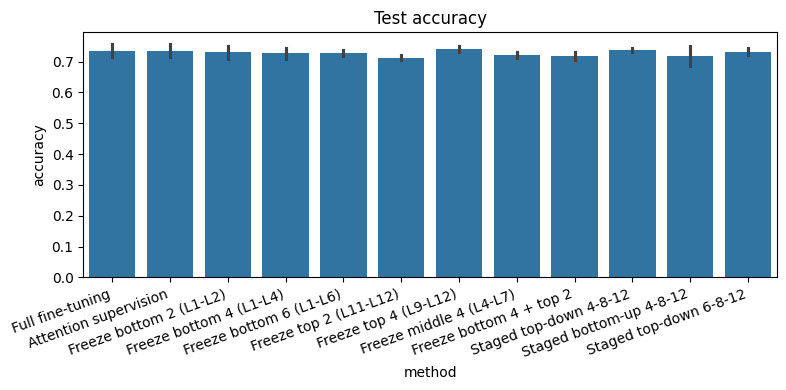

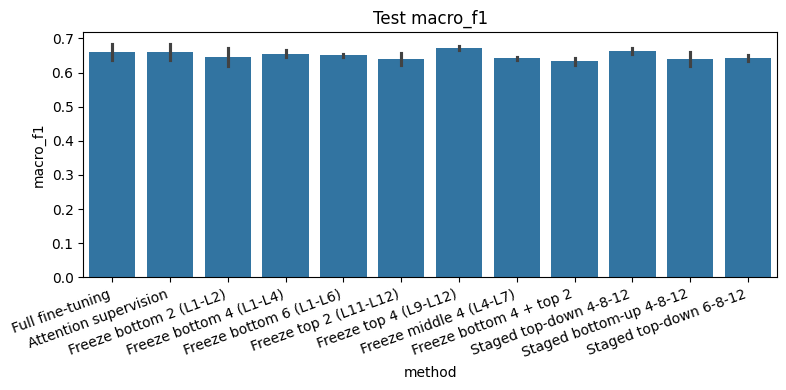

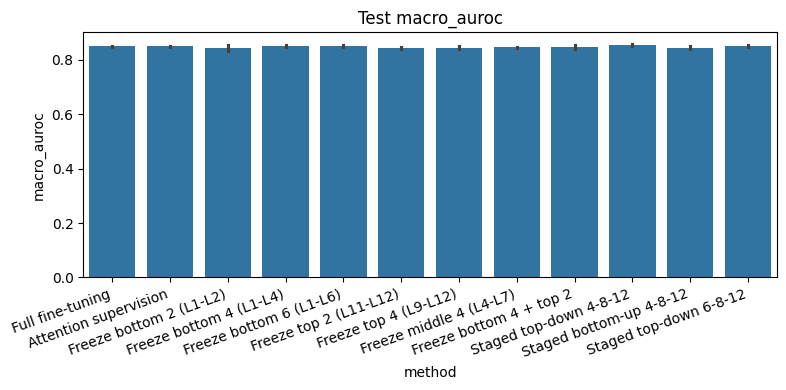

In [19]:
def plot_confusion(y, probs, title="Confusion matrix"):
    pred=probs.argmax(1)
    cm=confusion_matrix(y,pred,labels=[0,1,2])
    plt.figure(figsize=(5,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",
                xticklabels=[ID2LABEL[i] for i in range(3)],
                yticklabels=[ID2LABEL[i] for i in range(3)])
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(title); plt.show()

def plot_controller_history(controller):
    if controller is None or not controller.history:
        print("No controller history."); return
    hist=controller.history
    mat=np.zeros((len(hist),12))
    for t,h in enumerate(hist):
        mat[t,h["frozen_layers"]]=1
    plt.figure(figsize=(12,4))
    sns.heatmap(mat.T,cmap="Greens",cbar=True,
                yticklabels=[f"L{i+1}" for i in range(12)])
    plt.xlabel("Monitoring event"); plt.ylabel("Encoder layer")
    plt.title("RAGF-BERT frozen-layer timeline (green = frozen)")
    plt.show()

# Display confusion matrix and freezing timeline for the proposed method.
if "RAGF-BERT" in trained_models:
    ragf_model,ragf_outputs,ragf_controller=trained_models["RAGF-BERT"]
    y,probs=ragf_outputs[0],ragf_outputs[1]
    plot_confusion(y,probs,"RAGF-BERT — held-out test set")
    plot_controller_history(ragf_controller)

# Compare classification metrics across the actual test runs.
if len(results_df):
    for metric in ["accuracy","macro_f1","macro_auroc"]:
        if metric in results_df:
            plt.figure(figsize=(8,4))
            sns.barplot(data=results_df,x="method",y=metric,errorbar="sd")
            plt.xticks(rotation=20,ha="right")
            plt.title(f"Test {metric}")
            plt.tight_layout()
            plt.show()

# Optional faithfulness scores on a sample of the held-out test data.
if "RAGF-BERT" in trained_models:
    print("RAGF faithfulness:",faithfulness_scores(ragf_model,test_df,max_examples=300))


# If gold rationales are absent, show illustrative model-generated token explanations.
# These are not human-validated rationales and must not be reported as plausibility scores.
if "RAGF-BERT" not in trained_models and "Adaptive classification" in trained_models:
    explain_model = trained_models["Adaptive classification"][0]
    @torch.no_grad()
    def show_token_explanations(model, texts, n=5):
        model.eval()
        rows = []
        for text_value in list(texts)[:n]:
            enc = tokenizer(str(text_value), return_tensors="pt",
                            truncation=True, max_length=MAX_LENGTH)
            ids = enc["input_ids"].to(DEVICE)
            mask = enc["attention_mask"].to(DEVICE)
            logits, token_scores = model(ids, mask)
            probs = logits.softmax(-1)[0].cpu().numpy()
            toks = tokenizer.convert_ids_to_tokens(ids[0].cpu().tolist())
            special = tokenizer.get_special_tokens_mask(
                ids[0].cpu().tolist(), already_has_special_tokens=True
            )
            scores = token_scores[0].cpu().numpy()
            valid_idx = [j for j, flag in enumerate(special) if not flag and mask[0,j].item() == 1]
            top = sorted(valid_idx, key=lambda j: scores[j], reverse=True)[:5]
            rows.append({
                "text": str(text_value),
                "predicted_label": ID2LABEL[int(np.argmax(probs))],
                "confidence": float(np.max(probs)),
                "top_tokens": " ".join(toks[j] for j in top),
            })
        return pd.DataFrame(rows)

    display(show_token_explanations(explain_model, test_df["text"].tolist(), n=5))


## 13. Research checklist before publication

- [ ] Confirm the exact HateXplain release, label mapping, rationale format and split.
- [ ] Verify user's CSV labels and rationale availability; do not invent rationale masks.
- [ ] Remove duplicate texts before splitting; consider near-duplicate grouping.
- [ ] Reproduce the original method as closely as available code permits.
- [ ] Compare static freezing, gradual unfreezing and dynamic policies.
- [ ] Run five seeds and report mean ± standard deviation.
- [ ] Report per-class scores and class imbalance.
- [ ] Report all eight paper metrics with consistent definitions.
- [ ] Validate comprehensiveness/sufficiency perturbation choices.
- [ ] Report GPU time, peak memory and frozen-layer schedule.
- [ ] Use paired confidence intervals and avoid test-set tuning.
- [ ] Do not claim the private 3,199-example paper dataset was reproduced unless it was actually supplied.
- [ ] Do not claim novelty as "first" without a systematic literature review.

**Expected output files:** checkpoints (`.pt`), experiment histories (`.csv`), controller traces (`.json`), confusion matrices and final metric tables under `/kaggle/working/ragf_bert/`.

## 14. Export and interpret your results

After the experiment runner finishes, these files are saved in `/content/ragf_bert/`:

- `test_results.csv` — test metrics for each method and seed.
- `results_mean_std.csv` — mean and standard deviation across seeds.
- `*_history.csv` — per-epoch validation history.
- `*_best.pt` — selected model checkpoints.
- `*_controller.json` — adaptive freezing trace.

To download the main results from Colab:
```python
from google.colab import files
files.download('/content/ragf_bert/test_results.csv')
files.download('/content/ragf_bert/results_mean_std.csv')
```

**Interpretation:** higher accuracy, macro-F1, AUROC, token-F1, IOU-F1 and AUPRC are better. Higher comprehensiveness is better; lower sufficiency is better. The notebook's faithfulness scores are an approximate perturbation evaluation and should be described with the exact masking protocol above.

The paper's published Table 2 is a reference, not a matched baseline: it reports accuracy 0.7425/0.7492 and macro-F1 0.6883/0.6983 for baseline/proposed, respectively. Do not claim a direct improvement over those values unless you reproduce the same dataset, split, preprocessing and evaluation protocol. The results generated here are your measured results on your own held-out test split.


If no human token-level rationale annotations are found, the notebook automatically runs valid classification experiments instead of stopping with an error. It also prints sample model-generated token explanations. Those explanations are qualitative only; token-F1, IOU-F1 and AUPRC against human rationales remain unavailable until gold rationales are supplied.

- `run_status.json` — records whether gold rationale supervision was available and which claims this run supports.
